In [1]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
voxel_res = 2
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1]
n_jobs = 16
nthreads = 2

In [4]:
## Load and process clinical data
DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

# Process and load UCSF maps
ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

UCSF cohort description --> N = 367
Precentage of censoring: 39.24%

UPENN cohort description --> N = 496
Precentage of censoring: 2.82%

Log-rank test: chi-squared statistic of 12.477916843409249 (p=0.00041179115365043976)
INFO: The effect of site was found to be significant, applying a correction procedure


Performing permutation test for the C-index: 100%|██████████| 10/10 [00:00<00:00, 31.48it/s]


	C-index of  0.5342924496048814 (p=0.0)
	Log HR of the site effect = 0.28700472900893287
Log-rank test after correction: chi-squared statistic of 0.07015271368547941 (p=0.7911145589222199)



Loading UCSF maps: 100%|██████████| 367/367 [00:03<00:00, 103.22it/s]


In [5]:
# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

maps_all = np.vstack((maps_ucsf, maps_upenn))

Loading UPENN maps:   0%|          | 0/496 [00:00<?, ?it/s]

Loading UPENN maps: 100%|██████████| 496/496 [00:03<00:00, 137.30it/s]


# NMF

In [6]:
from TractDensityComponents import TD_PCA
from components import Projections

normalization = None#'min_max'
save_dir = "results/"
n_components = 10

td_pca = TD_PCA(maps_all, T1, binary_mask=T1_brain, n_components=n_components)
X = td_pca.training_maps

INFO:	TD maps were masked.


In [7]:
from sklearn.decomposition import NMF, MiniBatchNMF


model = NMF(n_components=n_components, init='random', random_state=0, max_iter=10, verbose=1)
W = model.fit_transform(X)
H = model.components_

violation: 1.0
violation: 1.7375636215135315
violation: 0.5582072835202372
violation: 0.31579523892041483
violation: 0.21926392876707393
violation: 0.17647886298221033
violation: 0.1315034250820819
violation: 0.09581822802296164
violation: 0.07485964148311083
violation: 0.061954734199065505


/home/joan/.conda/envs/neuro/lib/python3.10/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 10 reached. Increase it to improve convergence.
  warnings.warn(


Concordance Index: 0.6511


<Axes: title={'center': 'CoxPHFitter for NMF\nConcordance Index: 0.6511'}, xlabel='log(HR) (95% CI)'>

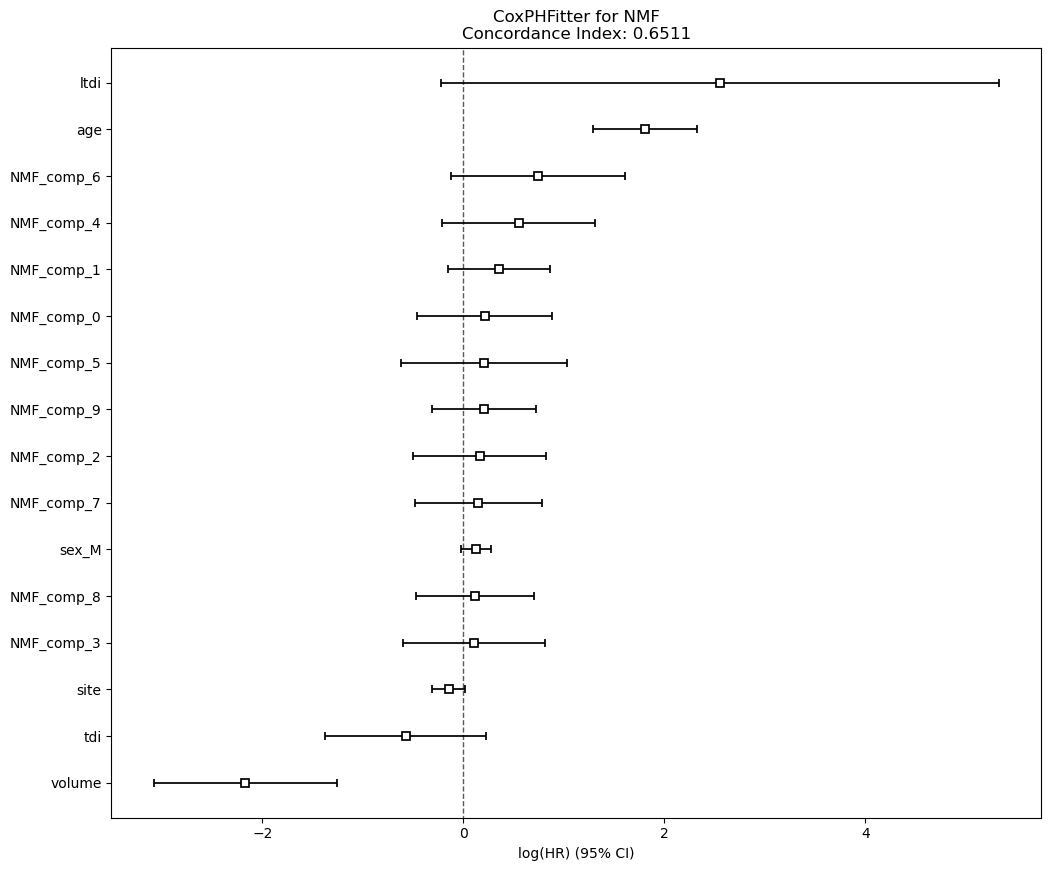

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    MinMaxScaler,
)
from feature_engine.encoding import (
    RareLabelEncoder,
)
import sklearn


column_names = [f'NMF_comp_{i}' for i in range(W.shape[1])]

df_nmf_weights = pd.DataFrame(W, columns=column_names)

df = pd.concat([DATA.reset_index(drop=True), df_nmf_weights], axis=1)
df = df.drop(columns=["OS"])

df.head()

feature_names = df.columns

categorical_features = df.select_dtypes(include="object").columns
numerical_features = df.select_dtypes(exclude="object").columns

numerical_features = numerical_features.drop(["OS (corrected)", "status"])

sklearn.set_config(transform_output="pandas")

one_hot_encoder = OneHotEncoder(
    drop="first",
    sparse_output=False,
    handle_unknown="ignore",
)
rle = RareLabelEncoder(n_categories=1, tol=0.01, missing_values='ignore')

categorical_pipeline = Pipeline(
    [
        ("rare_label_encoder", rle),
        ("one_hot_encoder", one_hot_encoder),
    ],
)

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

column_transformer = ColumnTransformer(
    [
        (
            "cat_pipeline",
            categorical_pipeline,
            categorical_features,
        )
    ],
    verbose_feature_names_out=False,
)

full_preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
],
    remainder='passthrough',
    verbose_feature_names_out=False,)

X = full_preprocessor.fit_transform(df)


from lifelines import CoxPHFitter

cph = CoxPHFitter(penalizer=0.01)
cph.fit(X, 'OS (corrected)', event_col='status')
print(f"Concordance Index: {cph.concordance_index_:.4f}")
# # cph.print_summary()
# cph.plot_covariate_groups('Whole lesion TDMap', values=[0, 1])
fig, ax = plt.subplots(figsize=(12, 10))
ax.set_title(f"CoxPHFitter for NMF\nConcordance Index: {cph.concordance_index_:.4f}")
cph.plot(ax = ax)

In [8]:
err = model.reconstruction_err_
print(f"Model reconstruction error for 10 components {err:.4f}")

import numpy as np


total_norm = np.linalg.norm(X)
relative_error = err / total_norm

print(f"Relative error: {relative_error:.4%}")
print(f"Explained variance (R^2 equivalent): {1 - (err/total_norm)**2:.4%}")

Model reconstruction error for 10 components 285687.1267
Relative error: 29.4168%
Explained variance (R^2 equivalent): 91.3465%


In [9]:
from nmf_projections import NMFProjections


nmf_proj = NMFProjections(W, H, T1, T1_brain)
output_dir = "results/nmf"
os.makedirs(output_dir, exist_ok=True)
output_filename = "nmf_loadings_4d.nii.gz"

nmf_proj.components_to_brain(
    save_dir=output_dir, 
    filename=output_filename, 
    verbose=True
)

DEBUG: components shape: (10, 265341)
DEBUG: n_components_: 10
DEBUG: expected total size: 10685920
INFO:	Unmasking NMF loadings into 3D space...
INFO:	Saved 4D NIfTI components at results/nmf/nmf_loadings_4d.nii.gz


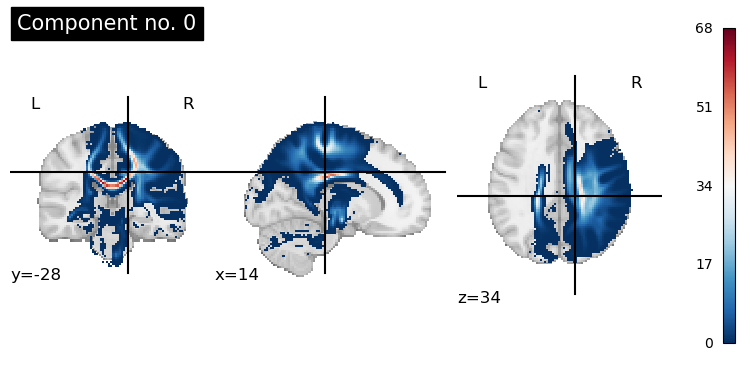

Max value in component 0: 67.84439086914062
Min value (should be 0 for NMF): 0.0


In [10]:
from nilearn import image

from nilearn import plotting

img_path = "results/nmf/nmf_loadings_4d.nii.gz"

no = 0
fourth_comp = image.index_img(img_path, no)

plotting.plot_stat_map(fourth_comp, title=f"Component no. {no}", threshold=0)
plotting.show()

data = fourth_comp.get_fdata()
print(f"Max value in component {no}: {data.max()}")
print(f"Min value (should be 0 for NMF): {data.min()}")

In [26]:
from TractDensityComponents import TD_PCA
from components import Projections

normalization = None#'min_max'
save_dir = "results/"
n_components = 10

td_pca = TD_PCA(maps_all, T1, binary_mask=T1_brain, n_components=n_components)
X = td_pca.training_maps


from sklearn.decomposition import NMF, MiniBatchNMF


sklearn.set_config(transform_output="default")

model = MiniBatchNMF(n_components=10, init='random', random_state=0, max_iter=10, verbose=1, batch_size=128)
W = model.fit_transform(X)
H = model.components_

INFO:	TD maps were masked.
Minibatch step 1/70: mean batch cost: 499744872.3824524
Minibatch step 2/70: mean batch cost: 306151826.0259878, ewa cost: 306151826.0259878
Minibatch step 3/70: mean batch cost: 302218028.80511975, ewa cost: 305569041.25252587
Minibatch step 4/70: mean batch cost: 320310229.1779818, ewa cost: 307752920.945186
Minibatch step 5/70: mean batch cost: 298754287.4315606, ewa cost: 306419790.05427855
Minibatch step 6/70: mean batch cost: 254930134.12552914, ewa cost: 298791692.879649
Minibatch step 7/70: mean batch cost: 326467676.51365393, ewa cost: 301834769.7838509
Minibatch step 8/70: mean batch cost: 299543913.1325548, ewa cost: 301495383.6132885
Minibatch step 9/70: mean batch cost: 299649468.5643446, ewa cost: 301221914.71714866
Minibatch step 10/70: mean batch cost: 292461710.65616125, ewa cost: 299924106.7081135
Minibatch step 11/70: mean batch cost: 313373141.98306626, ewa cost: 301916556.37847686
Minibatch step 12/70: mean batch cost: 292486403.03859454,

/home/joan/.conda/envs/neuro/lib/python3.10/site-packages/sklearn/decomposition/_nmf.py:2314: ConvergenceWarning: Maximum number of iterations 10 reached. Increase it to improve convergence.
  warnings.warn(


Concordance Index: 0.6501


<Axes: title={'center': 'CoxPHFitter for NMF\nConcordance Index: 0.6501'}, xlabel='log(HR) (95% CI)'>

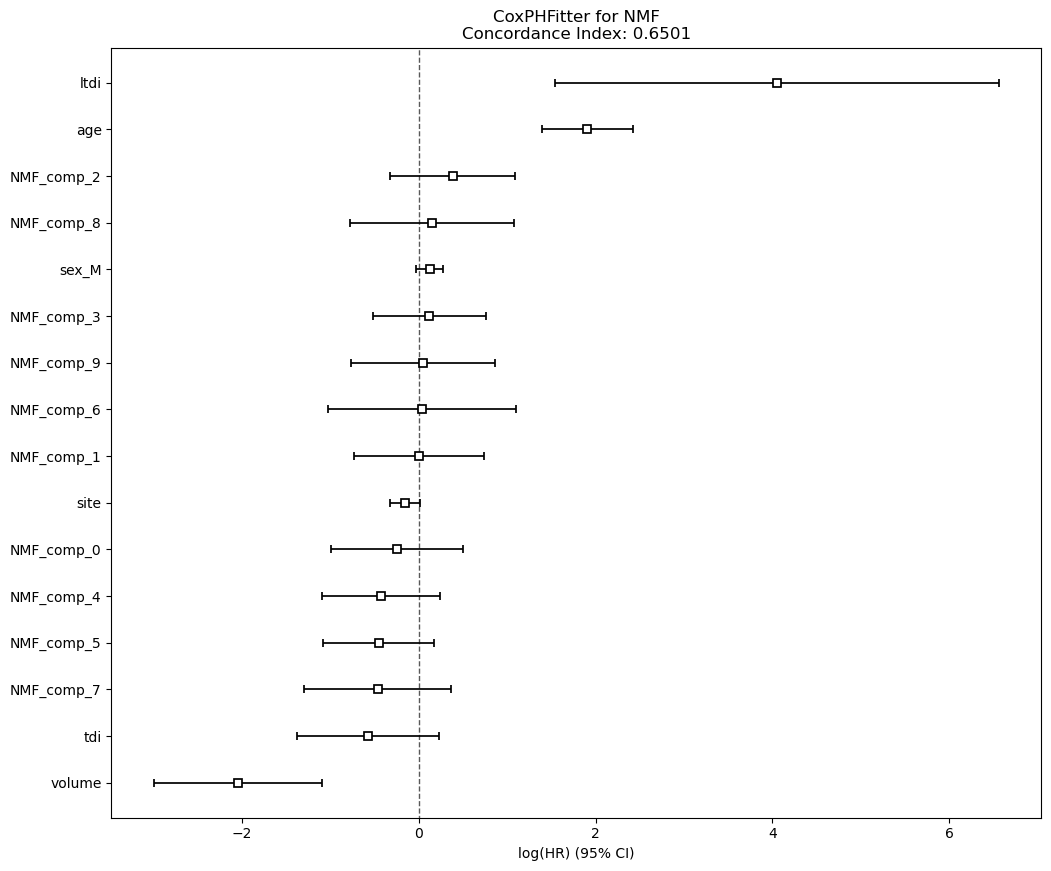

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    MinMaxScaler,
)
from feature_engine.encoding import (
    RareLabelEncoder,
)
import sklearn


column_names = [f'NMF_comp_{i}' for i in range(W.shape[1])]

df_nmf_weights = pd.DataFrame(W, columns=column_names)

df = pd.concat([DATA.reset_index(drop=True), df_nmf_weights], axis=1)
df = df.drop(columns=["OS"])

df.head()

feature_names = df.columns

categorical_features = df.select_dtypes(include="object").columns
numerical_features = df.select_dtypes(exclude="object").columns

numerical_features = numerical_features.drop(["OS (corrected)", "status"])

sklearn.set_config(transform_output="pandas")

one_hot_encoder = OneHotEncoder(
    drop="first",
    sparse_output=False,
    handle_unknown="ignore",
)
rle = RareLabelEncoder(n_categories=1, tol=0.01, missing_values='ignore')

categorical_pipeline = Pipeline(
    [
        ("rare_label_encoder", rle),
        ("one_hot_encoder", one_hot_encoder),
    ],
)

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

column_transformer = ColumnTransformer(
    [
        (
            "cat_pipeline",
            categorical_pipeline,
            categorical_features,
        )
    ],
    verbose_feature_names_out=False,
)

full_preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
],
    remainder='passthrough',
    verbose_feature_names_out=False,)

X = full_preprocessor.fit_transform(df)


from lifelines import CoxPHFitter

cph = CoxPHFitter(penalizer=0.01)
cph.fit(X, 'OS (corrected)', event_col='status')
print(f"Concordance Index: {cph.concordance_index_:.4f}")
# # cph.print_summary()
# cph.plot_covariate_groups('Whole lesion TDMap', values=[0, 1])
fig, ax = plt.subplots(figsize=(12, 10))
ax.set_title(f"CoxPHFitter for NMF\nConcordance Index: {cph.concordance_index_:.4f}")
cph.plot(ax = ax)

In [13]:
from nmf_projections import NMFProjections


nmf_proj = NMFProjections(W, H, T1, T1_brain)
output_dir = "results/nmf"
os.makedirs(output_dir, exist_ok=True)
output_filename = "nmf_minibatch_loadings_4d.nii.gz"

nmf_proj.components_to_brain(
    save_dir=output_dir, 
    filename=output_filename, 
    verbose=True
)

DEBUG: components shape: (10, 265341)
DEBUG: n_components_: 10
DEBUG: expected total size: 10685920
INFO:	Unmasking NMF loadings into 3D space...
INFO:	Saved 4D NIfTI components at results/nmf/nmf_minibatch_loadings_4d.nii.gz


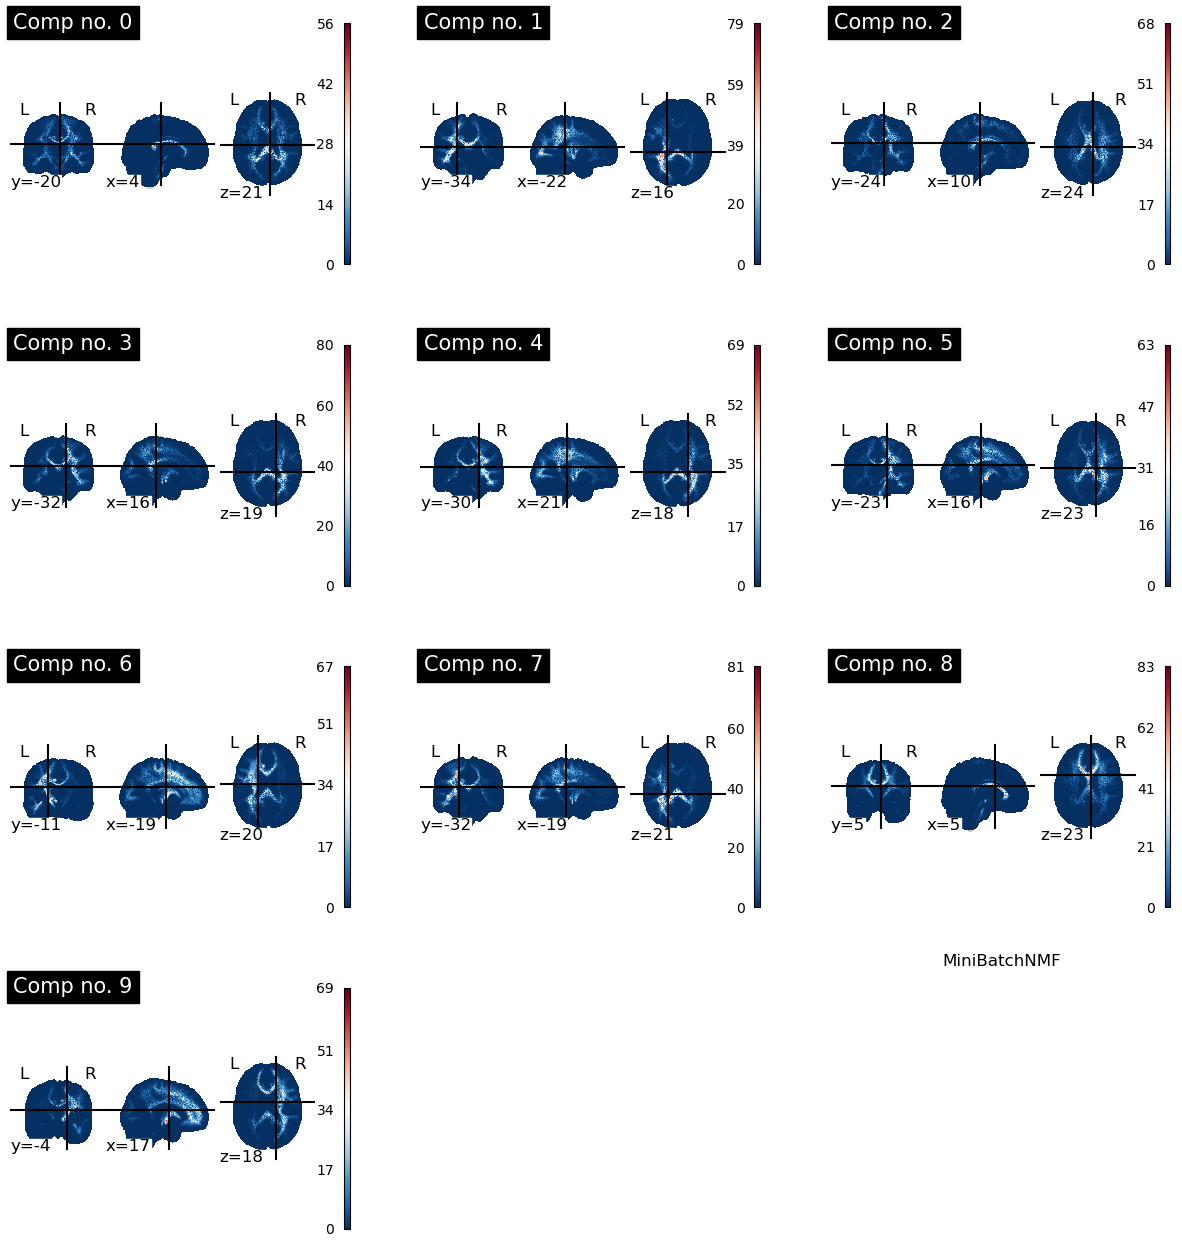

In [14]:
import matplotlib.pyplot as plt
from nilearn import image, plotting

img_path = "results/nmf/nmf_minibatch_loadings_4d.nii.gz"
n_components = 10

n_cols = 3
n_rows = (n_components + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
plt.title("MiniBatchNMF")
axes = axes.flatten()

for i in range(n_components):
    comp_img = image.index_img(img_path, i)
    
    plotting.plot_stat_map(
        comp_img, 
        title=f"Comp no. {i}", 
        threshold=0, 
        axes=axes[i], 
        # display_mode='z',
        # cut_coords=1,
        colorbar=True
    )


for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.show()

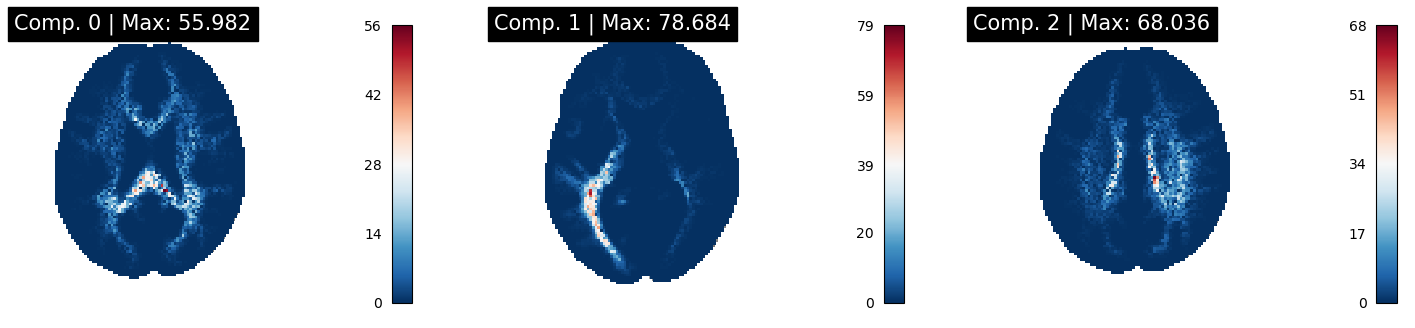

In [21]:
import matplotlib.pyplot as plt
from nilearn import image, plotting


img_path = "results/nmf/nmf_minibatch_loadings_4d.nii.gz"
n_components = 3

n_cols = 3
n_rows = (n_components + n_cols - 1) // n_cols

fig = plt.figure(figsize=(18, 4 * n_rows))

for i in range(n_components):
    comp_img = image.index_img(img_path, i)
    vmax = comp_img.get_fdata().max()
    
    ax = fig.add_subplot(n_rows, n_cols, i + 1)
    
    plotting.plot_stat_map(
        comp_img, 
        title=f"Comp. {i} | Max: {vmax:.3f}", 
        threshold=0,
        axes=ax, 
        colorbar=True,
        display_mode='z', 
        cut_coords=1,
        annotate=False
    )

plt.subplots_adjust(hspace=0.3, wspace=0.1)
plotting.show()

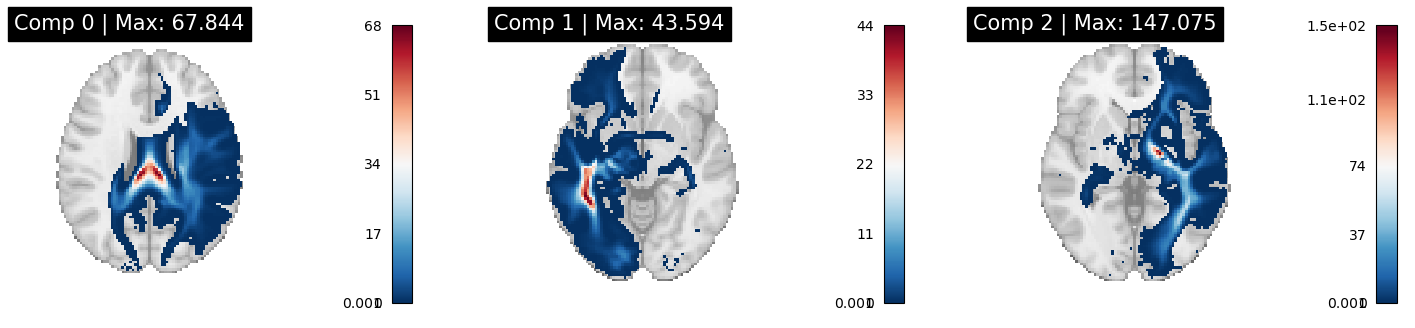

In [19]:
import matplotlib.pyplot as plt
from nilearn import image, plotting


img_path = "results/nmf/nmf_loadings_4d.nii.gz"
n_components = 3

n_cols = 3
n_rows = (n_components + n_cols - 1) // n_cols

fig = plt.figure(figsize=(18, 4 * n_rows))

for i in range(n_components):
    comp_img = image.index_img(img_path, i)
    vmax = comp_img.get_fdata().max()
    
    ax = fig.add_subplot(n_rows, n_cols, i + 1)
    
    plotting.plot_stat_map(
        comp_img, 
        title=f"Comp {i} | Max: {vmax:.3f}", 
        threshold=0.001,
        axes=ax, 
        colorbar=True,
        display_mode='z', 
        cut_coords=1,
        annotate=False
    )

plt.subplots_adjust(hspace=0.3, wspace=0.1)
plotting.show()